--- Ý 1: DỮ LIỆU CƠ BẢN ---
Hệ số chặn (Intercept): [542.24212764]
Hệ số góc (Slope): [[34.96753034]]
MSE: 36710.13
R^2 score: 0.9615



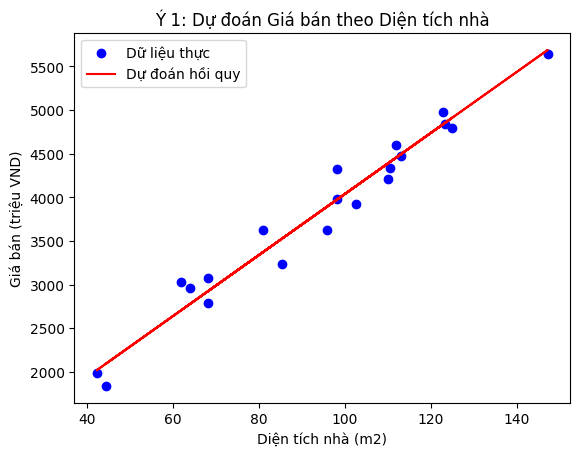

--- Ý 2: NHIỀU DỮ LIỆU & NHIỄU CAO ---
Hệ số chặn (Intercept): [619.51536464]
Hệ số góc (Slope): [[33.83896783]]
MSE: 497854.68
R^2 score: 0.7514

--- Ý 3: HỒI QUY ĐA BIẾN (3 BIẾN ĐẦU VÀO) ---
Hệ số chặn (Intercept): 521.13
Hệ số hồi quy (Coefficients): [ 35.04798083 144.18540278 -42.4194443 ]
MSE: 34010.10
R^2 score: 0.9775


In [16]:
#Bai 1
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

# ==========================================
# Ý 1: HỒI QUY ĐƠN GIẢN (Diện tích -> Giá bán)
# ==========================================
np.random.seed(0)
# Giả sử 100 căn nhà, diện tích từ 30 đến 150 m2
X = 30 + 120 * np.random.rand(100, 1)
# Giá bán = 500 + 35 * Diện tích + nhiễu
y = 500 + 35 * X + 200 * np.random.randn(100, 1)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("--- Ý 1: DỮ LIỆU CƠ BẢN ---")
print(f"Hệ số chặn (Intercept): {model.intercept_}")
print(f"Hệ số góc (Slope): {model.coef_}")
print(f"MSE: {mean_squared_error(y_test, y_pred):.2f}")
print(f"R^2 score: {r2_score(y_test, y_pred):.4f}\n")

# Vẽ biểu đồ Ý 1
plt.scatter(X_test, y_test, color="blue", label="Dữ liệu thực")
plt.plot(X_test, y_pred, color="red", label="Dự đoán hồi quy")
plt.title("Ý 1: Dự đoán Giá bán theo Diện tích nhà")
plt.xlabel("Diện tích nhà (m2)")
plt.ylabel("Giá bán (triệu VND)")
plt.legend()
plt.show()

# ==========================================
# Ý 2: THÊM SỐ LƯỢNG DỮ LIỆU VÀ ĐỘ NHIỄU
# ==========================================
np.random.seed(0)
X_large = 30 + 120 * np.random.rand(1000, 1) # Tăng lên 1000 mẫu
y_noisy = 500 + 35 * X_large + 800 * np.random.randn(1000, 1) # Tăng nhiễu lên 800

X_train, X_test, y_train, y_test = train_test_split(X_large, y_noisy, test_size=0.2, random_state=42)

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("--- Ý 2: NHIỀU DỮ LIỆU & NHIỄU CAO ---")
print(f"Hệ số chặn (Intercept): {model.intercept_}")
print(f"Hệ số góc (Slope): {model.coef_}")
print(f"MSE: {mean_squared_error(y_test, y_pred):.2f}")
print(f"R^2 score: {r2_score(y_test, y_pred):.4f}\n")

# ==========================================
# Ý 3: THÊM BIẾN ĐẦU VÀO (HỒI QUY ĐA BIẾN)
# (Dựa trên phần 2 trong code mẫu của bạn)
# ==========================================
np.random.seed(0)
# Tạo 3 biến đầu vào cho 1000 căn nhà:
# Cột 0: Diện tích (30 - 150 m2)
# Cột 1: Số phòng ngủ (1 - 5 phòng)
# Cột 2: Khoảng cách tới trung tâm (1 - 20 km)
X_multi = np.zeros((1000, 3))
X_multi[:, 0] = 30 + 120 * np.random.rand(1000)
X_multi[:, 1] = np.random.randint(1, 6, size=1000)
X_multi[:, 2] = 1 + 19 * np.random.rand(1000)

# Công thức giá bán phụ thuộc cả 3 biến (Đã sửa lỗi kích thước mảng từ code mẫu)
y_multi = 500 + 35 * X_multi[:, 0] + 150 * X_multi[:, 1] - 40 * X_multi[:, 2] + 200 * np.random.randn(1000)

X_train, X_test, y_train, y_test = train_test_split(X_multi, y_multi, test_size=0.2, random_state=42)

model_multi = LinearRegression()
model_multi.fit(X_train, y_train)
y_pred_multi = model_multi.predict(X_test)

print("--- Ý 3: HỒI QUY ĐA BIẾN (3 BIẾN ĐẦU VÀO) ---")
print(f"Hệ số chặn (Intercept): {model_multi.intercept_:.2f}")
print(f"Hệ số hồi quy (Coefficients): {model_multi.coef_}")
print(f"MSE: {mean_squared_error(y_test, y_pred_multi):.2f}")
print(f"R^2 score: {r2_score(y_test, y_pred_multi):.4f}")

--- KẾT QUẢ BÀI 2: DỰ ĐOÁN MẮC BỆNH THEO BMI ---
BMI: 27.3 -> Xác suất mắc bệnh: 54.6% | Dự đoán: 1 (Thực tế: 1)
BMI: 19.6 -> Xác suất mắc bệnh: 0.0% | Dự đoán: 0 (Thực tế: 0)
BMI: 30.2 -> Xác suất mắc bệnh: 95.6% | Dự đoán: 1 (Thực tế: 1)
BMI: 20.9 -> Xác suất mắc bệnh: 0.2% | Dự đoán: 0 (Thực tế: 0)
BMI: 15.2 -> Xác suất mắc bệnh: 0.0% | Dự đoán: 0 (Thực tế: 0)

Độ chính xác (Accuracy): 0.9750
Ma trận nhầm lẫn (Confusion Matrix):
[[19  0]
 [ 1 20]]


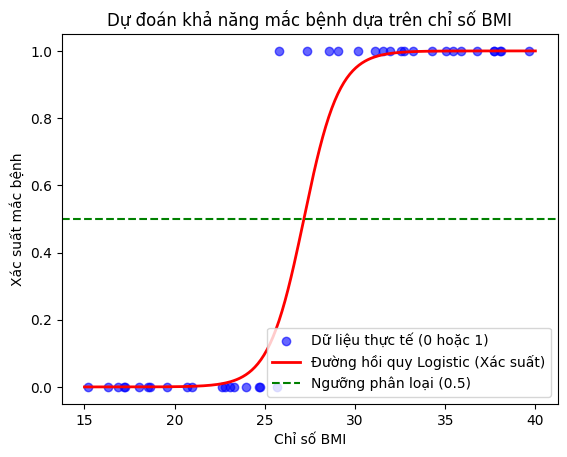

In [14]:
#Bai 2
# Thư viện
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Tải dữ liệu hoa Iris trong thư viện sklearn
iris = load_iris()
X = iris['data'] # Các đặc trưng (features)
y = iris['target'] # Các nhãn (target)

# Chọn ra hai loại hoa (0 và 1) để thực hiện phân loại nhị phân
X = X[y != 2] # Loại bỏ lớp 2
y = y[y != 2] # Chỉ giữ lại lớp 0 và 1

# Chia dữ liệu (minh họa chia 80% huấn luyên và 20% kiểm tra)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Tạo mô hình Logistic Regression
model = LogisticRegression()

# Huấn luyện mô hình trên tập huấn luyện
model.fit(X_train, y_train)

# Dự đoán trên tập kiểm tra
y_pred = model.predict(X_test)

# Đánh giá mô hình
accuracy = accuracy_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)
class_report = classification_report(y_test, y_pred)

# In kết quả
print(f"Độ chính xác (Accuracy): {accuracy}")
print("Ma trận nhầm lẫn (Confusion Matrix):")
print(conf_matrix)
print("Báo cáo phân loại (Classification Report):")
print(class_report)

--- 5 DÒNG DỮ LIỆU ĐẦU TIÊN ---
   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  MedHouseVal  
0    -122.23        4.526  
1    -122.22        3.585  
2    -122.24        3.521  
3    -122.25        3.413  
4    -122.25        3.422  

--- KIỂM TRA DỮ LIỆU BỊ THIẾU (MISSING VALUES) ---
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

--- KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH ---
Hệ số chặn (Intercept): 2.0719
Mean Squared Error (MSE): 0.5559
Root Mean Squared Error (RM

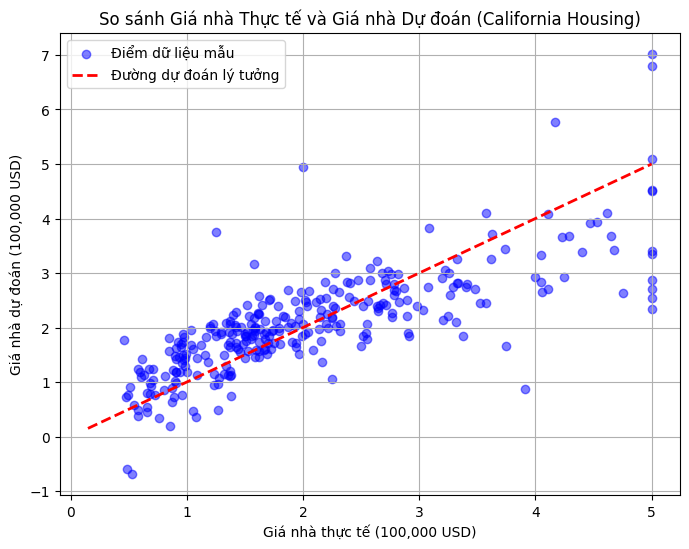

In [15]:
#Bai 3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# ==============================================================================
# BƯỚC 1: TẢI VÀ KHÁM PHÁ BỘ DỮ LIỆU (California Housing - Phổ biến trên Kaggle)
# ==============================================================================
housing = fetch_california_housing(as_frame=True)
df = housing.frame

print("--- 5 DÒNG DỮ LIỆU ĐẦU TIÊN ---")
print(df.head())

print("\n--- KIỂM TRA DỮ LIỆU BỊ THIẾU (MISSING VALUES) ---")
print(df.isnull().sum())

# ==============================================================================
# BƯỚC 2: TIỀN XỬ LÝ DỮ LIỆU (TÁCH BIẾN & CHUẨN HÓA)
# ==============================================================================
# X: 8 đặc trưng (Thu nhập trung bình, tuổi nhà, số phòng trung bình,...)
# y: Giá nhà trung bình (đơn vị: 100,000 USD)
X = df.drop(columns=['MedHouseVal'])
y = df['MedHouseVal']

# Chia tập dữ liệu: 80% Huấn luyện - 20% Kiểm tra
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Chuẩn hóa dữ liệu (Standardization) giúp các biến có cùng thang đo
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# ==============================================================================
# BƯỚC 3: XÂY DỰNG VÀ HUẤN LUYỆN MÔ HÌNH HỒI QUY TUYẾN TÍNH
# ==============================================================================
model = LinearRegression()
model.fit(X_train_scaled, y_train)

# ==============================================================================
# BƯỚC 4: DỰ ĐOÁN VÀ ĐÁNH GIÁ MÔ HÌNH
# ==============================================================================
y_pred = model.predict(X_test_scaled)

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("\n--- KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH ---")
print(f"Hệ số chặn (Intercept): {model.intercept_:.4f}")
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"R^2 Score: {r2:.4f}")

# Xem mức độ ảnh hưởng của từng đặc trưng đến giá nhà
coef_df = pd.DataFrame({'Đặc trưng': X.columns, 'Trọng số (Coef)': model.coef_})
print("\n--- MỨC ĐỘ ẢNH HƯỞNG CỦA CÁC BIẾN ---")
print(coef_df.sort_values(by='Trọng số (Coef)', ascending=False))

# ==============================================================================
# BƯỚC 5: TRỰC QUAN HÓA KẾT QUẢ DỰ ĐOÁN
# ==============================================================================
plt.figure(figsize=(8, 6))
plt.scatter(y_test[:300], y_pred[:300], color='blue', alpha=0.5, label='Điểm dữ liệu mẫu')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red', linestyle='--', linewidth=2, label='Đường dự đoán lý tưởng')
plt.title("So sánh Giá nhà Thực tế và Giá nhà Dự đoán (California Housing)")
plt.xlabel("Giá nhà thực tế (100,000 USD)")
plt.ylabel("Giá nhà dự đoán (100,000 USD)")
plt.legend()
plt.grid(True)
plt.show()